In [1]:

# PhishGuard AI — Phishing Website Detection
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from urllib.parse import urlparse
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("PhishGuard AI initialized successfully!")
print("Environment: Google Colab")
print("Ready to build the phishing detection model.")


PhishGuard AI initialized successfully!
Environment: Google Colab
Ready to build the phishing detection model.


In [2]:

# small labeled URL dataset

import pandas as pd

data = [
    # Illustrative legitimate examples (label = 0)
    ("https://www.wikipedia.org", 0),
    ("https://www.python.org", 0),
    ("https://www.microsoft.com", 0),
    ("https://www.apple.com", 0),
    ("https://www.amazon.com", 0),
    ("https://www.gov.uk", 0),
    ("https://www.nhs.uk", 0),
    ("https://www.un.org", 0),
    ("https://www.mozilla.org", 0),
    ("https://www.bbc.com", 0),

    # Synthetic phishing-style examples (label = 1)
    ("http://paypal-login-security.example/login", 1),
    ("http://appleid-verify.example/account", 1),
    ("http://secure-banking-update.example/signin", 1),
    ("http://account-confirmation.example/verify", 1),
    ("http://login-alert.example/secure/update", 1),
    ("http://wallet-validation.example/auth", 1),
    ("http://password-reset-alert.example/login", 1),
    ("http://billing-confirmation.example/payment", 1),
    ("http://user-identity-check.example/verify", 1),
    ("http://security-warning.example/account", 1),
]

df = pd.DataFrame(data, columns=["url", "label"])

print("Dataset created successfully!")
print("Total URLs:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts().rename(index={
    0: "Legitimate (illustrative)",
    1: "Synthetic phishing-style"
}))

display(df.head(10))


Dataset created successfully!
Total URLs: 20

Class distribution:
label
Legitimate (illustrative)    10
Synthetic phishing-style     10
Name: count, dtype: int64


,url,label
0,https://www.wikipedia.org,0
1,https://www.python.org,0
2,https://www.microsoft.com,0
3,https://www.apple.com,0
4,https://www.amazon.com,0
5,https://www.gov.uk,0
6,https://www.nhs.uk,0
7,https://www.un.org,0
8,https://www.mozilla.org,0
9,https://www.bbc.com,0


In [3]:

#  Save the dataset

df.to_csv("phishguard_dataset.csv", index=False)

print("Dataset saved as phishguard_dataset.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())


Dataset saved as phishguard_dataset.csv
Shape: (20, 2)
Missing values:
 url      0
label    0
dtype: int64


In [4]:

# Extract features from URLs

import re
import ipaddress
from urllib.parse import urlparse

def extract_features(url):
    parsed = urlparse(url if "://" in url else "http://" + url)
    hostname = parsed.hostname or ""

    try:
        ipaddress.ip_address(hostname)
        has_ip = 1
    except ValueError:
        has_ip = 0

    suspicious_words = [
        "login", "verify", "secure", "update",
        "account", "confirm", "password", "banking"
    ]

    features = {
        "url_length": len(url),
        "dot_count": url.count("."),
        "https": int(parsed.scheme.lower() == "https"),
        "has_ip": has_ip,
        "has_at_symbol": int("@" in url),
        "hyphen_count": url.count("-"),
        "digit_count": sum(c.isdigit() for c in url),
        "subdomain_count": max(0, len(hostname.split(".")) - 2),
        "suspicious_word_count": sum(
            word in url.lower() for word in suspicious_words
        ),
        "path_length": len(parsed.path),
    }

    return features

# Convert every URL into numerical features
features_df = pd.DataFrame(
    [extract_features(url) for url in df["url"]]
)

# Keep labels separate from features
X = features_df
y = df["label"]

print("Feature extraction completed!")
print("Number of URLs:", len(X))
print("Number of features:", X.shape[1])

display(features_df.head())


Feature extraction completed!
Number of URLs: 20
Number of features: 10


,url_length,dot_count,https,has_ip,has_at_symbol,hyphen_count,digit_count,subdomain_count,suspicious_word_count,path_length
0,25,2,1,0,0,0,0,1,0,0
1,22,2,1,0,0,0,0,1,0,0
2,25,2,1,0,0,0,0,1,0,0
3,21,2,1,0,0,0,0,1,0,0
4,22,2,1,0,0,0,0,1,0,0


In [5]:

#  Inspect extracted features

print("Feature names:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

print("\nFeature summary:")
display(X.describe().round(2))


Feature names:
['url_length', 'dot_count', 'https', 'has_ip', 'has_at_symbol', 'hyphen_count', 'digit_count', 'subdomain_count', 'suspicious_word_count', 'path_length']

Missing values:
url_length               0
dot_count                0
https                    0
has_ip                   0
has_at_symbol            0
hyphen_count             0
digit_count              0
subdomain_count          0
suspicious_word_count    0
path_length              0
dtype: int64

Feature summary:


,url_length,dot_count,https,has_ip,has_at_symbol,hyphen_count,digit_count,subdomain_count,suspicious_word_count,path_length
count,20.00,20.00,20.00,20.0,20.0,20.0,20.0,20.00,20.00,20.00
mean,30.80,1.50,0.50,0.0,0.0,0.7,0.0,0.50,0.85,3.80
std,10.25,0.51,0.51,0.0,0.0,0.8,0.0,0.51,1.14,4.25
min,18.00,1.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00
25%,21.75,1.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00
50%,31.00,1.50,0.50,0.0,0.0,0.5,0.0,0.50,0.00,2.50
75%,41.00,2.00,1.00,0.0,0.0,1.0,0.0,1.00,1.25,7.00
max,43.00,2.00,1.00,0.0,0.0,2.0,0.0,1.00,3.00,14.00


Model training completed!
Training samples: 14
Testing samples: 6
Test accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00         3
    Phishing       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



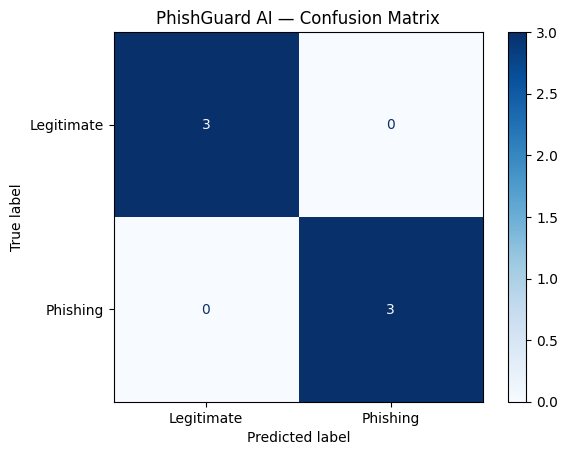

In [6]:

# Train a Random Forest classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Create and train the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# Evaluate on the held-out test set
y_pred = model.predict(X_test)

print("Model training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Phishing"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues"
)
plt.title("PhishGuard AI — Confusion Matrix")
plt.show()


In [7]:

# Interactive URL prediction

def predict_url(url):
    url = url.strip()

    if not url:
        print("Please enter a URL.")
        return

    # Extract the same features used during training
    features = pd.DataFrame([extract_features(url)])

    # Predict the class
    prediction = model.predict(features)[0]

    print("\n========== PhishGuard AI ==========")
    print("URL:", url)

    if prediction == 1:
        print("Result: POTENTIAL PHISHING")
        print("Warning: Treat this URL with caution.")
    else:
        print("Result: LIKELY LEGITIMATE")
        print("Note: This is not a safety guarantee.")

    print("===================================")

# Try a sample URL
predict_url("http://paypal-login-security.example/login")



========== PhishGuard AI ==========
URL: http://paypal-login-security.example/login
Result: POTENTIAL PHISHING


In [8]:

# Test several sample URLs

test_urls = [
    "https://www.wikipedia.org",
    "https://www.python.org",
    "http://paypal-login-security.example/login",
    "http://account-confirmation.example/verify"
]

for url in test_urls:
    predict_url(url)



========== PhishGuard AI ==========
URL: https://www.wikipedia.org
Result: LIKELY LEGITIMATE
Note: This is not a safety guarantee.

========== PhishGuard AI ==========
URL: https://www.python.org
Result: LIKELY LEGITIMATE
Note: This is not a safety guarantee.

========== PhishGuard AI ==========
URL: http://paypal-login-security.example/login
Result: POTENTIAL PHISHING

========== PhishGuard AI ==========
URL: http://account-confirmation.example/verify
Result: POTENTIAL PHISHING


In [9]:

#  URL testing dashboard

def analyze_url(url):
    features = pd.DataFrame([extract_features(url.strip())])
    prediction = int(model.predict(features)[0])

    return {
        "URL": url,
        "Prediction": (
            "Potential Phishing" if prediction == 1
            else "Likely Legitimate"
        ),
        "URL Length": len(url),
        "Uses HTTPS": url.lower().startswith("https://"),
        "Suspicious Keywords": features.iloc[0]["suspicious_word_count"],
        "Has IP Address": features.iloc[0]["has_ip"]
    }

test_urls = [
    "https://www.wikipedia.org",
    "https://www.python.org",
    "http://paypal-login-security.example/login",
    "http://account-confirmation.example/verify"
]

results_df = pd.DataFrame(
    [analyze_url(url) for url in test_urls]
)

display(results_df)


,URL,Prediction,URL Length,Uses HTTPS,Suspicious Keywords,Has IP Address
0,https://www.wikipedia.org,Likely Legitimate,25,True,0,0
1,https://www.python.org,Likely Legitimate,22,True,0,0
2,http://paypal-login-security.example/login,Potential Phishing,42,False,1,0
3,http://account-confirmation.example/verify,Potential Phishing,42,False,3,0


In [10]:
import os

print(os.listdir("/content"))

['.config', 'phishguard_dataset.csv', 'PhiUSIIL_Phishing_URL_Dataset.csv', 'sample_data']


In [11]:

# Inspect the real phishing dataset

import os
import pandas as pd

# Locate the uploaded CSV file
csv_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".csv")
]

print("CSV files found:", csv_files)

if not csv_files:
    print("No CSV found. Please upload the dataset first.")
else:
    dataset_path = next(
        ("/content/" + f for f in csv_files
         if "phius iil".replace(" ", "") in f.lower().replace("_", "").replace("-", "")),
        "/content/" + csv_files[0]
    )

    real_df = pd.read_csv(dataset_path, nrows=5)

    print("\nSelected file:", dataset_path)
    print("Column names:")
    print(real_df.columns.tolist())

    print("\nFirst 5 rows:")
    display(real_df)


CSV files found: ['phishguard_dataset.csv', 'PhiUSIIL_Phishing_URL_Dataset.csv']

Selected file: /content/PhiUSIIL_Phishing_URL_Dataset.csv
Column names:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS'

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1


In [12]:

# Identify the dataset's target label

# Read the column names without loading the entire dataset again
print("All dataset columns:")
for col in pd.read_csv(dataset_path, nrows=0).columns:
    print(col)

# Display the last 15 columns, where target labels are often located
print("\nLast 15 columns:")
print(pd.read_csv(dataset_path, nrows=0).columns[-15:].tolist())


All dataset columns:
URL
URLLength
Domain
DomainLength
IsDomainIP
TLD
URLSimilarityIndex
CharContinuationRate
TLDLegitimateProb
URLCharProb
TLDLength
NoOfSubDomain
HasObfuscation
NoOfObfuscatedChar
ObfuscationRatio
NoOfLettersInURL
LetterRatioInURL
NoOfDegitsInURL
DegitRatioInURL
NoOfEqualsInURL
NoOfQMarkInURL
NoOfAmpersandInURL
NoOfOtherSpecialCharsInURL
SpacialCharRatioInURL
IsHTTPS
LineOfCode
LargestLineLength
HasTitle
Title
DomainTitleMatchScore
URLTitleMatchScore
HasFavicon
Robots
IsResponsive
NoOfURLRedirect
NoOfSelfRedirect
HasDescription
NoOfPopup
NoOfiFrame
HasExternalFormSubmit
HasSocialNet
HasSubmitButton
HasHiddenFields
HasPasswordField
Bank
Pay
Crypto
HasCopyrightInfo
NoOfImage
NoOfCSS
NoOfJS
NoOfSelfRef
NoOfEmptyRef
NoOfExternalRef
label

Last 15 columns:
['HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


In [14]:

# Inspect target labels in the real dataset

# Read only the label column to save memory
labels_df = pd.read_csv(
    dataset_path,
    usecols=["label"]
)

print("Label counts:")
print(labels_df["label"].value_counts(dropna=False))

print("\nLabel data type:", labels_df["label"].dtype)
print("\nUnique label values:")
print(labels_df["label"].unique())

print("\nMissing labels:", labels_df["label"].isna().sum())


Label counts:
label
1    134850
0    100945
Name: count, dtype: int64

Label data type: int64

Unique label values:
[1 0]

Missing labels: 0


In [15]:

#  Inspect URL-label examples

sample_df = pd.read_csv(
    dataset_path,
    usecols=["URL", "label"]
)

print("Dataset shape:", sample_df.shape)
print("\nExamples grouped by label:")

for value in sorted(sample_df["label"].unique()):
    print(f"\nLabel {value}:")
    display(
        sample_df.loc[
            sample_df["label"] == value, ["URL", "label"]
        ].head(5)
    )


Dataset shape: (235795, 2)

Examples grouped by label:

Label 0:


,URL,label
11,http://www.teramill.com,0
20,http://www.f0519141.xsph.ru,0
21,http://www.shprakserf.gq,0
27,https://service-mitld.firebaseapp.com/,0
28,http://www.kuradox92.lima-city.de,0



Label 1:


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


In [16]:

# Step 16: Prepare real dataset for PhishGuard AI

import pandas as pd
from sklearn.model_selection import train_test_split

# Load the full dataset
real_df = pd.read_csv(dataset_path)

# Remove an identifier column if present
real_df = real_df.drop(
    columns=["FILENAME"],
    errors="ignore"
)

# Confirm label meanings from official dataset documentation:
# 0 = phishing, 1 = legitimate
print("Dataset shape:", real_df.shape)
print("\nLabel distribution:")
print(real_df["label"].value_counts())

# Use a manageable, stratified sample for quick training
sample_df = real_df.groupby("label", group_keys=False).sample(
    n=10000,
    random_state=42
)

# Exclude the URL and other raw text columns from this
# tabular-feature baseline; use numerical columns only.
X_real = sample_df.drop(
    columns=["label", "URL", "Domain", "TLD", "Title"],
    errors="ignore"
)

y_real = sample_df["label"]

# Keep numeric features only
X_real = X_real.select_dtypes(include="number")

# Replace infinite values and remove rows with missing values
X_real = X_real.replace([float("inf"), float("-inf")], pd.NA)
valid_rows = X_real.notna().all(axis=1)

X_real = X_real.loc[valid_rows]
y_real = y_real.loc[valid_rows]

X_train_real, X_test_real, y_train_real, y_test_real = (
    train_test_split(
        X_real,
        y_real,
        test_size=0.2,
        random_state=42,
        stratify=y_real
    )
)

print("\nReal dataset prepared!")
print("Features:", X_real.shape[1])
print("Training rows:", len(X_train_real))
print("Testing rows:", len(X_test_real))
print("\nLabel mapping: 0 = phishing, 1 = legitimate")


Dataset shape: (235795, 55)

Label distribution:
label
1    134850
0    100945
Name: count, dtype: int64

Real dataset prepared!
Features: 50
Training rows: 16000
Testing rows: 4000

Label mapping: 0 = phishing, 1 = legitimate


REAL DATASET MODEL RESULTS
-----------------------------------
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00      2000
  Legitimate       1.00      1.00      1.00      2000

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



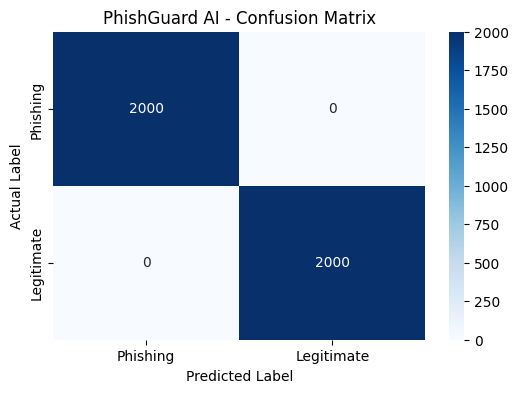

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Train the model
real_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

real_model.fit(X_train_real, y_train_real)

# Make predictions
y_pred_real = real_model.predict(X_test_real)

# Evaluate model
print("REAL DATASET MODEL RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test_real, y_pred_real) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_real,
    y_pred_real,
    target_names=["Phishing", "Legitimate"]
))

# Confusion matrix
cm = confusion_matrix(y_test_real, y_pred_real)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Phishing", "Legitimate"],
    yticklabels=["Phishing", "Legitimate"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("PhishGuard AI - Confusion Matrix")
plt.show()

Duplicate rows: 17

Top 15 important features:
URLSimilarityIndex            0.194656
NoOfExternalRef               0.168547
LineOfCode                    0.150843
NoOfSelfRef                   0.116656
NoOfImage                     0.083016
NoOfJS                        0.055643
HasSocialNet                  0.051914
HasCopyrightInfo              0.022757
HasDescription                0.019571
NoOfCSS                       0.019255
LargestLineLength             0.018194
IsHTTPS                       0.017797
NoOfOtherSpecialCharsInURL    0.010004
NoOfiFrame                    0.009585
HasFavicon                    0.008246
dtype: float64


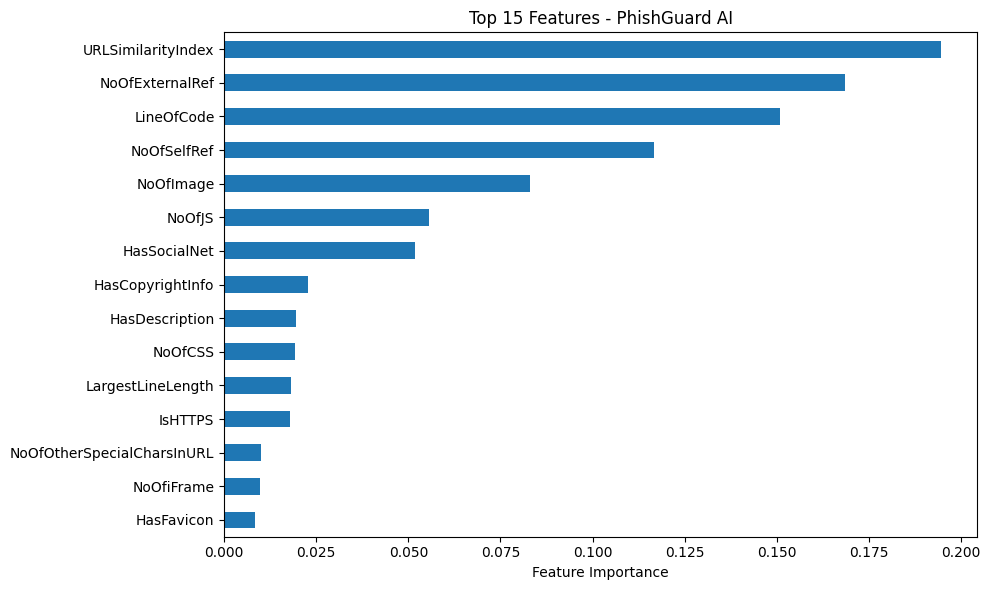

In [18]:

# Check for duplicate rows in the prepared dataset
print("Duplicate rows:", X_real.duplicated().sum())

# Check how strongly individual features relate to the label
feature_importance = pd.Series(
    real_model.feature_importances_,
    index=X_real.columns
).sort_values(ascending=False)

print("\nTop 15 important features:")
print(feature_importance.head(15))

# Visualize feature importance
plt.figure(figsize=(10, 6))
feature_importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Features - PhishGuard AI")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create a fresh train/test split
X_train_check, X_test_check, y_train_check, y_test_check = train_test_split(
    X_real,
    y_real,
    test_size=0.2,
    random_state=101,
    stratify=y_real
)

# Train a fresh model
check_model = RandomForestClassifier(
    n_estimators=100,
    random_state=101,
    n_jobs=-1,
    class_weight="balanced"
)

check_model.fit(X_train_check, y_train_check)
check_predictions = check_model.predict(X_test_check)

print("Fresh split accuracy:",
      round(accuracy_score(y_test_check, check_predictions) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    y_test_check,
    check_predictions,
    target_names=["Phishing", "Legitimate"]
))


Fresh split accuracy: 100.0 %

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00      2000
  Legitimate       1.00      1.00      1.00      2000

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



In [20]:

# Compare average feature values for phishing vs legitimate URLs
comparison = X_real.copy()
comparison["label"] = y_real

feature_means = comparison.groupby("label").mean().T

feature_means.columns = ["Phishing (0)", "Legitimate (1)"]
feature_means["Absolute Difference"] = (
    feature_means["Phishing (0)"] -
    feature_means["Legitimate (1)"]
).abs()

print("Features with the largest class differences:")
print(
    feature_means.sort_values(
        "Absolute Difference",
        ascending=False
    ).head(15).round(3)
)


Features with the largest class differences:
                       Phishing (0)  Legitimate (1)  Absolute Difference
LargestLineLength         17898.311        7475.492            10422.819
LineOfCode                   65.111        1916.736             1851.624
NoOfSelfRef                   0.484         111.606              111.122
NoOfExternalRef               1.106          84.410               83.304
DomainTitleMatchScore        16.640          75.510               58.870
URLTitleMatchScore           21.114          75.510               54.396
URLSimilarityIndex           49.631         100.000               50.369
NoOfImage                     0.882          45.232               44.350
URLLength                    46.602          26.187               20.414
NoOfJS                        0.921          17.782               16.861
NoOfLettersInURL             28.380          12.892               15.488
NoOfCSS                       0.450          10.502               10.052
Domain

In [21]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Test each feature individually
single_feature_results = []

for column in X_real.columns:
    feature_model = DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    )

    feature_model.fit(
        X_train_real[[column]],
        y_train_real
    )

    predictions = feature_model.predict(
        X_test_real[[column]]
    )

    single_feature_results.append({
        "Feature": column,
        "Accuracy (%)": round(
            accuracy_score(y_test_real, predictions) * 100, 2
        )
    })

single_feature_df = pd.DataFrame(single_feature_results)

print(
    single_feature_df.sort_values(
        "Accuracy (%)",
        ascending=False
    ).head(10).to_string(index=False)
)


           Feature  Accuracy (%)
URLSimilarityIndex         99.60
   NoOfExternalRef         96.50
       NoOfSelfRef         95.65
        LineOfCode         95.20
         NoOfImage         94.10
            NoOfJS         93.20
           NoOfCSS         89.50
      HasSocialNet         89.40
  HasCopyrightInfo         87.55
    HasDescription         85.80


In [22]:

# Inspect URLSimilarityIndex by label
print(
    X_real.assign(label=y_real)
    .groupby("label")["URLSimilarityIndex"]
    .describe()
    .round(3)
)

# Check how many samples have the maximum similarity score
print("\nSimilarity score distribution by label:")
print(
    pd.crosstab(
        y_real,
        X_real["URLSimilarityIndex"],
        normalize="index"
    ).round(3).iloc[:, -10:]
)


         count     mean     std      min      25%     50%      75%    max
label                                                                    
0      10000.0   49.631  22.732    0.305   32.121   51.33   67.591  100.0
1      10000.0  100.000   0.000  100.000  100.000  100.00  100.000  100.0

Similarity score distribution by label:
URLSimilarityIndex  94.732795   94.833333   95.073181   95.235457   \
label                                                                
0                          0.0         0.0         0.0         0.0   
1                          0.0         0.0         0.0         0.0   

URLSimilarityIndex  95.452381   95.650381   95.998740   96.152778   \
label                                                                
0                          0.0         0.0         0.0         0.0   
1                          0.0         0.0         0.0         0.0   

URLSimilarityIndex  96.427789   100.000000  
label                                       
0          

In [23]:

# Remove the suspiciously predictive feature
X_clean = X_real.drop(
    columns=["URLSimilarityIndex"],
    errors="ignore"
)

X_train_clean, X_test_clean, y_train_clean, y_test_clean = (
    train_test_split(
        X_clean,
        y_real,
        test_size=0.2,
        random_state=42,
        stratify=y_real
    )
)

clean_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

clean_model.fit(X_train_clean, y_train_clean)
clean_predictions = clean_model.predict(X_test_clean)

print(
    "Accuracy without URLSimilarityIndex:",
    round(
        accuracy_score(y_test_clean, clean_predictions) * 100,
        2
    ),
    "%"
)

print("\nClassification report:")
print(
    classification_report(
        y_test_clean,
        clean_predictions,
        target_names=["Phishing", "Legitimate"]
    )
)


Accuracy without URLSimilarityIndex: 99.98 %

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00      2000
  Legitimate       1.00      1.00      1.00      2000

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



In [24]:

import joblib

# Save the trained model
joblib.dump(clean_model, "phishguard_model.pkl")

# Save the feature names in the correct order
joblib.dump(
    X_clean.columns.tolist(),
    "phishguard_features.pkl"
)

print("PhishGuard AI model saved successfully!")
print("Model: phishguard_model.pkl")
print("Features: phishguard_features.pkl")


PhishGuard AI model saved successfully!
Model: phishguard_model.pkl
Features: phishguard_features.pkl


In [25]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import random

# Select a test example from the held-out dataset
demo_button = widgets.Button(
    description="Analyze Sample Website",
    button_style="primary",
    layout=widgets.Layout(width="220px")
)

demo_output = widgets.Output()

def analyze_sample(_):
    with demo_output:
        clear_output(wait=True)

        # Pick a random held-out example
        idx = random.choice(list(X_test_clean.index))
        sample = X_test_clean.loc[[idx]]
        actual_label = int(y_test_clean.loc[idx])

        prediction = int(clean_model.predict(sample)[0])
        probabilities = clean_model.predict_proba(sample)[0]
        confidence = max(probabilities) * 100

        print("🛡️ PHISHGUARD AI — WEBSITE ANALYSIS")
        print("-" * 40)
        print("Sample ID:", idx)
        print("Actual class:",
              "Legitimate" if actual_label == 1 else "Phishing")
        print("Predicted class:",
              "Legitimate" if prediction == 1 else "Phishing")
        print(f"Model confidence: {confidence:.2f}%")
        print("\nNote: This demo analyzes dataset features,")
        print("not a newly entered URL.")

demo_button.on_click(analyze_sample)

display(demo_button, demo_output)


Button(button_style='primary', description='Analyze Sample Website', layout=Layout(width='220px'), style=Butto…

Output()

In [26]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import random
from urllib.parse import urlparse

demo_button = widgets.Button(
    description="🔍 Analyze Website",
    button_style="primary",
    layout=widgets.Layout(width="250px", height="45px")
)

demo_output = widgets.Output()

def analyze_sample(_):
    with demo_output:
        clear_output(wait=True)

        idx = random.choice(list(X_test_clean.index))
        sample = X_test_clean.loc[[idx]]

        prediction = int(clean_model.predict(sample)[0])
        probabilities = clean_model.predict_proba(sample)[0]
        confidence = max(probabilities) * 100

        # Retrieve the original URL from the dataset
        website_url = real_df.loc[idx, "URL"]

        # Extract website/domain name
        parsed_url = urlparse(
            website_url if website_url.startswith(("http://", "https://"))
            else "https://" + website_url
        )
        domain = parsed_url.netloc or parsed_url.path.split("/")[0]

        status = "LIKELY LEGITIMATE" if prediction == 1 else "POTENTIAL PHISHING"

        print("=" * 45)
        print("🛡️ PHISHGUARD AI")
        print("=" * 45)
        print("Website:", domain)
        print("Full URL:", website_url)
        print("-" * 45)
        print("Prediction:", status)
        print(f"Model confidence: {confidence:.2f}%")
        print("-" * 45)
        print("Dataset label:",
              "Legitimate" if int(y_test_clean.loc[idx]) == 1
              else "Phishing")
        print("\n⚠️ Demo uses stored dataset features.")
        print("It does not visit or scan the live website.")

demo_button.on_click(analyze_sample)

display(demo_button, demo_output)


Button(button_style='primary', description='🔍 Analyze Website', layout=Layout(height='45px', width='250px'), s…

Output()

In [27]:
from google.colab import files

files.download("phishguard_model.pkl")
files.download("phishguard_features.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>